# DOTA Oriented Object Detection

In [ ]:
import json, shutil, subprocess, sys, zipfile, urllib.request
from pathlib import Path

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "shapely"], check=True)
from ultralytics import YOLO
from ultralytics.data.split_dota import split_trainval

In [ ]:
TMP, OUT = Path("/tmp/dota"), Path("/kaggle/working/results")
TMP.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
HOURS, IMG, SEED = 10.0, 1024, 0

In [ ]:
zp = TMP / "DOTAv1.zip"
urllib.request.urlretrieve("https://github.com/ultralytics/assets/releases/download/v0.0.0/DOTAv1.zip", zp)
with zipfile.ZipFile(zp) as z:
    z.extractall(TMP)
zp.unlink()
root = next(p.parent.parent for p in TMP.rglob("images/train"))
split_trainval(data_root=str(root), save_dir=str(TMP / "split"), crop_size=IMG, gap=200, rates=[1.0])
shutil.rmtree(root)  # free disk: only tiles are needed from here

In [ ]:
names = ["plane", "ship", "storage tank", "baseball diamond", "tennis court", "basketball court",
         "ground track field", "harbor", "bridge", "large vehicle", "small vehicle", "helicopter",
         "roundabout", "soccer ball field", "swimming pool"]
yaml = TMP / "dota.yaml"
yaml.write_text(f"path: {TMP / 'split'}\ntrain: images/train\nval: images/val\nnames:\n" +
                "".join(f"  {i}: {n}\n" for i, n in enumerate(names)))
for s in ["train", "val"]:
    print(s, "tiles:", len(list((TMP / "split/images" / s).glob("*"))), flush=True)

In [ ]:
try:
    model, base = YOLO("yolo26m-obb.yaml").load("yolo26m.pt"), "yolo26m (COCO)"
except Exception:
    model, base = YOLO("yolo11m-obb.yaml").load("yolo11m.pt"), "yolo11m (COCO)"

model.train(data=str(yaml), imgsz=IMG, epochs=100, time=HOURS, batch=8, seed=SEED, cos_lr=True,
            degrees=180, flipud=0.5, fliplr=0.5, mosaic=1.0, close_mosaic=3, val=False,
            project="/tmp/runs", name="dota", exist_ok=True, plots=True, verbose=False, workers=4)

In [ ]:
w = Path("/tmp/runs/dota/weights/last.pt")
m = YOLO(str(w)).val(data=str(yaml), imgsz=IMG, batch=8, split="val", plots=True,
                     project="/tmp/runs", name="val", exist_ok=True)
per_class = {names[c]: round(float(m.box.maps[c]), 4) for c in range(len(names))}
ap50 = {names[int(c)]: round(float(m.box.all_ap[i, 0]), 4) for i, c in enumerate(m.box.ap_class_index)}  # classes present in val
report = {
    "task": "oriented bounding boxes, DOTA-v1, 15 classes",
    "base_weights": base, "image_tiles": f"{IMG}px, 200px overlap, single scale",
    "train_hours": HOURS, "validation": "official DOTA-v1 val split (never trained on), tile level",
    "mAP50": round(float(m.box.map50), 4), "mAP50_95": round(float(m.box.map), 4),
    "precision": round(float(m.box.mp), 4), "recall": round(float(m.box.mr), 4),
    "ap50_per_class": ap50, "map50_95_per_class": per_class,
}
(OUT / "metrics.json").write_text(json.dumps(report, indent=2))
print(json.dumps(report, indent=2))

In [ ]:
shutil.copy(w, OUT / "dota_obb_last.pt")
for d in [Path("/tmp/runs/dota"), Path("/tmp/runs/val")]:
    for f in d.glob("*.png"):
        shutil.copy(f, OUT / f"{d.name}_{f.name}")
    for f in list(d.glob("val_batch*_pred.jpg"))[:3]:
        shutil.copy(f, OUT / f.name)

In [ ]:
import cv2, numpy as np

urllib.request.urlretrieve("https://github.com/ultralytics/assets/releases/download/v0.0.0/dota8.zip", TMP / "dota8.zip")
with zipfile.ZipFile(TMP / "dota8.zip") as z:
    z.extractall(TMP)
model = YOLO(str(w))
palette = [(230, 25, 75), (60, 180, 75), (255, 225, 25), (0, 130, 200), (245, 130, 48), (145, 30, 180),
           (70, 240, 240), (240, 50, 230), (210, 245, 60), (250, 190, 212), (0, 128, 128), (220, 190, 255),
           (170, 110, 40), (255, 250, 200), (128, 0, 0)]  # RGB, one per class

results = [model.predict(str(p), imgsz=IMG, conf=0.35, verbose=False)[0]
           for p in sorted((TMP / "dota8/images").rglob("*.jpg"))]
results = sorted(results, key=lambda r: -len(r.obb))[:2]  # the two busiest tiles
tiles, seen = [], set()
for r in results:
    img = r.orig_img.copy()
    for poly, c in zip(r.obb.xyxyxyxy.cpu().numpy(), r.obb.cls.cpu().numpy().astype(int)):
        seen.add(c)
        cv2.polylines(img, [poly.astype(np.int32)], True, palette[c][::-1], 3, cv2.LINE_AA)
    tiles.append(cv2.resize(img, (720, 720), interpolation=cv2.INTER_AREA))
grid = np.hstack(tiles)
legend = np.full((110, grid.shape[1], 3), 255, np.uint8)
x, y = 20, 20
for c in sorted(seen):
    w_ = 32 + cv2.getTextSize(names[c], cv2.FONT_HERSHEY_SIMPLEX, 0.75, 2)[0][0] + 30
    if x + w_ > grid.shape[1]:  # wrap to a second row
        x, y = 20, y + 45
    cv2.rectangle(legend, (x, y), (x + 24, y + 24), palette[c][::-1], -1)
    cv2.putText(legend, names[c], (x + 32, y + 21), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (30, 30, 30), 2, cv2.LINE_AA)
    x += w_
cv2.imwrite(str(OUT / "sample_predictions.jpg"), np.vstack([grid, legend[:y + 45]]), [cv2.IMWRITE_JPEG_QUALITY, 88])
print("objects per tile:", [len(r.obb) for r in results])

In [ ]:
import matplotlib.pyplot as plt
import torch

hist = torch.load(w, weights_only=False, map_location="cpu")["train_results"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, k in zip(axes, ["box_loss", "cls_loss", "angle_loss"]):
    tr = hist[f"train/{k}"]
    ax.plot(range(1, len(tr) + 1), tr, marker="o", ms=3, label="train")
    ax.plot(len(tr), hist[f"val/{k}"][-1], "s", color="C3", label="val (end of training)")
    ax.set_title(k.replace("_", " ")); ax.set_xlabel("epoch"); ax.grid(alpha=.3)
axes[0].legend()
fig.tight_layout(); fig.savefig(OUT / "training_curves.png", dpi=130); plt.show()

| metric | value |
|---|---|
| **mAP50** | **0.818** |
| mAP50-95 | 0.649 |
| precision | 0.805 |
| recall | 0.761 |

| class | AP50 | AP50-95 |
|---|---|---|
| plane | 0.982 | 0.873 |
| ship | 0.974 | 0.805 |
| tennis court | 0.950 | 0.923 |
| large vehicle | 0.907 | 0.738 |
| harbor | 0.890 | 0.622 |
| storage tank | 0.882 | 0.704 |
| baseball diamond | 0.843 | 0.654 |
| small vehicle | 0.830 | 0.643 |
| basketball court | 0.820 | 0.751 |
| ground track field | 0.783 | 0.672 |
| roundabout | 0.776 | 0.593 |
| swimming pool | 0.719 | 0.473 |
| soccer ball field | 0.660 | 0.530 |
| bridge | 0.633 | 0.398 |
| helicopter | 0.622 | 0.360 |


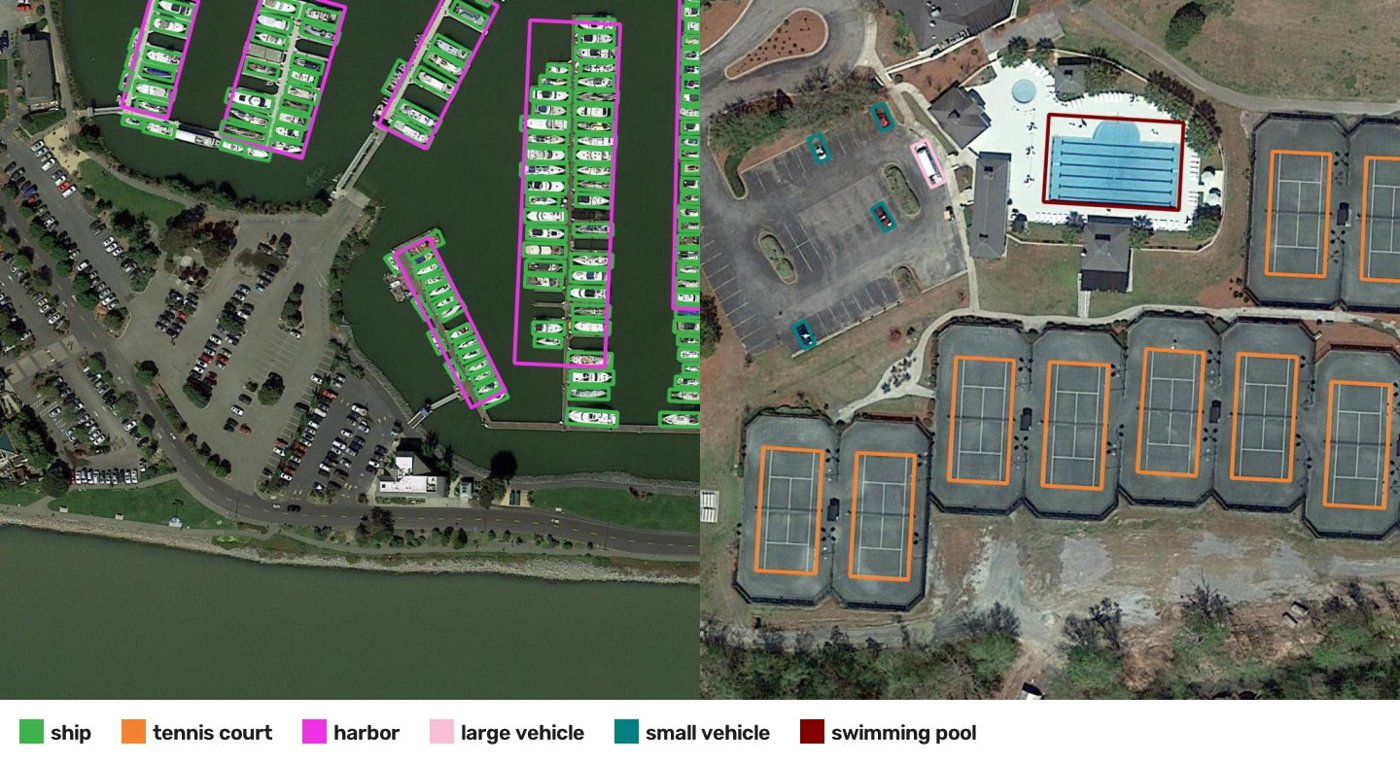

*Predicted rotated boxes on two DOTA8 tiles: a marina and a sports club*

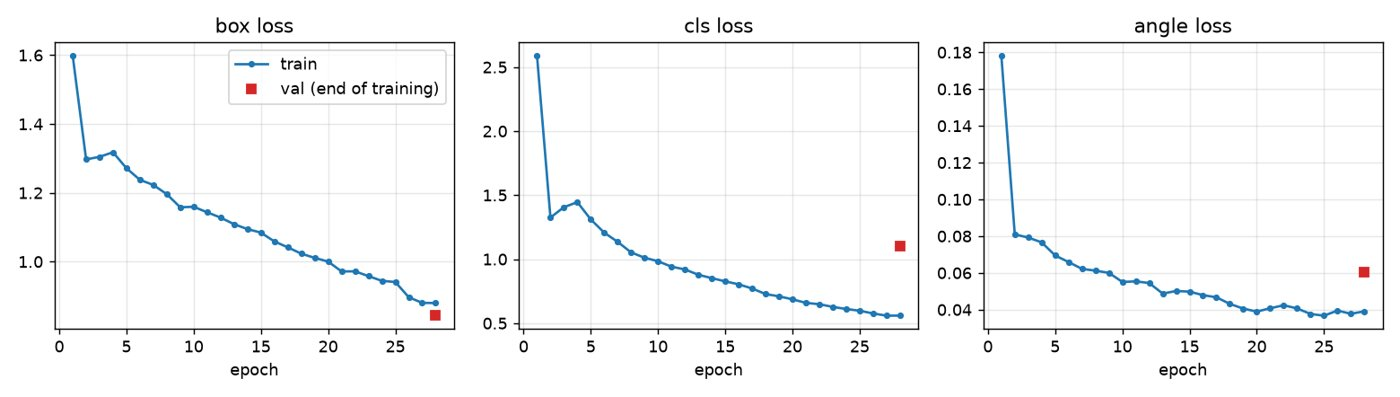

*Training losses per epoch; red square = validation loss at the end*

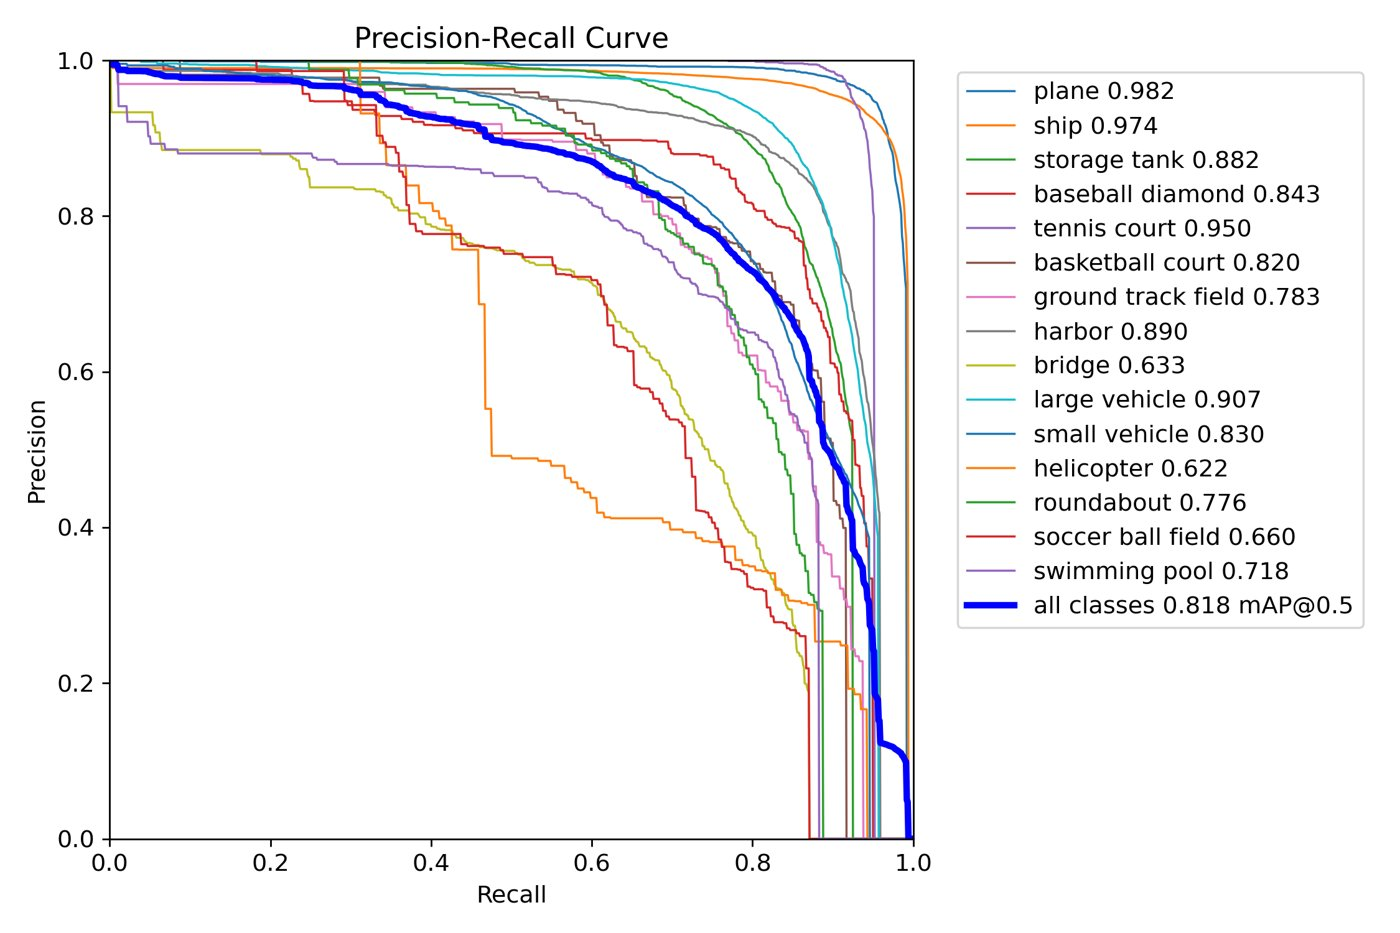

*Precision-recall curve per class on the val split*